# <font color="orange"> Análisis de los datos a la universidad </font>

## PARTE 1: Visualización de grafos con NetworkX

### Apartado 1.1: Construcción del grafo de relaciones

In [6]:
import json
from collections import Counter

import networkx as nx
import matplotlib.pyplot as plt

RUTA_DATOS = "game-of-thrones-master/data/"

with open(RUTA_DATOS + "characters.json", encoding="utf-8") as f:
    personajes = json.load(f)["characters"]

print("Nº de personajes:", len(personajes))

# Qué claves (atributos y relaciones) aparecen y en cuántos personajes
claves = Counter(k for p in personajes for k in p)
for clave, n in claves.most_common():
    print(f"{clave} {n}")


Nº de personajes: 389
characterName 389
characterLink 368
actorName 354
actorLink 353
characterImageThumb 255
characterImageFull 255
killedBy 190
houseName 88
killed 80
siblings 57
parents 56
marriedEngaged 43
parentOf 37
royal 17
actors 16
serves 15
guardianOf 12
nickname 9
guardedBy 9
kingsguard 5
allies 5
servedBy 4
abductedBy 1
abducted 1


In [7]:

RELACIONES = {
    "killed":         ("conflicto", True,  False),
    "killedBy":       ("conflicto", True,  True),
    "parentOf":       ("familia",   True,  False),
    "parents":        ("familia",   True,  True),
    "siblings":       ("familia",   False, False),
    "marriedEngaged": ("familia",   False, False),
}


NOMBRE_RELACION = {"killedBy": "killed", "parents": "parentOf"}

def obtener_casa(personaje):
    casa = personaje.get("houseName")
    if casa is None:
        return "Sin casa"
    elif isinstance(casa, list):
        return casa[0]
    return casa



G = nx.MultiDiGraph()

#un nodo por personaje, con su casa como atributo
for p in personajes:
    G.add_node(p["characterName"], casa=obtener_casa(p))


def ya_existe(G, u, v, relacion):
    """True si ya hay una arista u->v con esa relación."""
    aristas = G.get_edge_data(u, v)
    if aristas is None:
        return False
    return any(d["relacion"] == relacion for d in aristas.values())


for p in personajes:
    origen = p["characterName"]
    for clave, (tipo, dirigida, invertir) in RELACIONES.items():
        relacion = NOMBRE_RELACION.get(clave, clave)

        for destino in p.get(clave, []):
            # Solo personajes de characters.json (así todos tienen atributo casa)
            if destino not in G:
                continue

            u, v = (destino, origen) if invertir else (origen, destino)

            # En las no dirigidas el otro personaje trae la arista al revés
            if ya_existe(G, u, v, relacion) or (not dirigida and ya_existe(G, v, u, relacion)):
                continue

            G.add_edge(u, v, tipo=tipo, relacion=relacion, dirigida=dirigida)


print("Nodos:", G.number_of_nodes(), "| Aristas:", G.number_of_edges())

print("\nAristas por relación:")
for rel, n in Counter(d["relacion"] for _, _, d in G.edges(data=True)).most_common():
    print(f"  {rel:15s} {n}")

print("\nNodos por casa:")
for casa, n in Counter(nx.get_node_attributes(G, "casa").values()).most_common():
    print(f"  {casa:15s} {n}")


Nodos: 370 | Aristas: 361

Aristas por relación:
  killed          180
  parentOf        82
  siblings        71
  marriedEngaged  28

Nodos por casa:
  Sin casa        282
  Stark           22
  Targaryen       11
  Lannister       10
  Baratheon       10
  Martell         8
  Frey            6
  Greyjoy         5
  Tyrell          4
  Tully           3
  Mormont         3
  Bolton          3
  Arryn           1
  Umber           1
  Tarly           1


Nodos dibujados: 219 | Aristas: 361


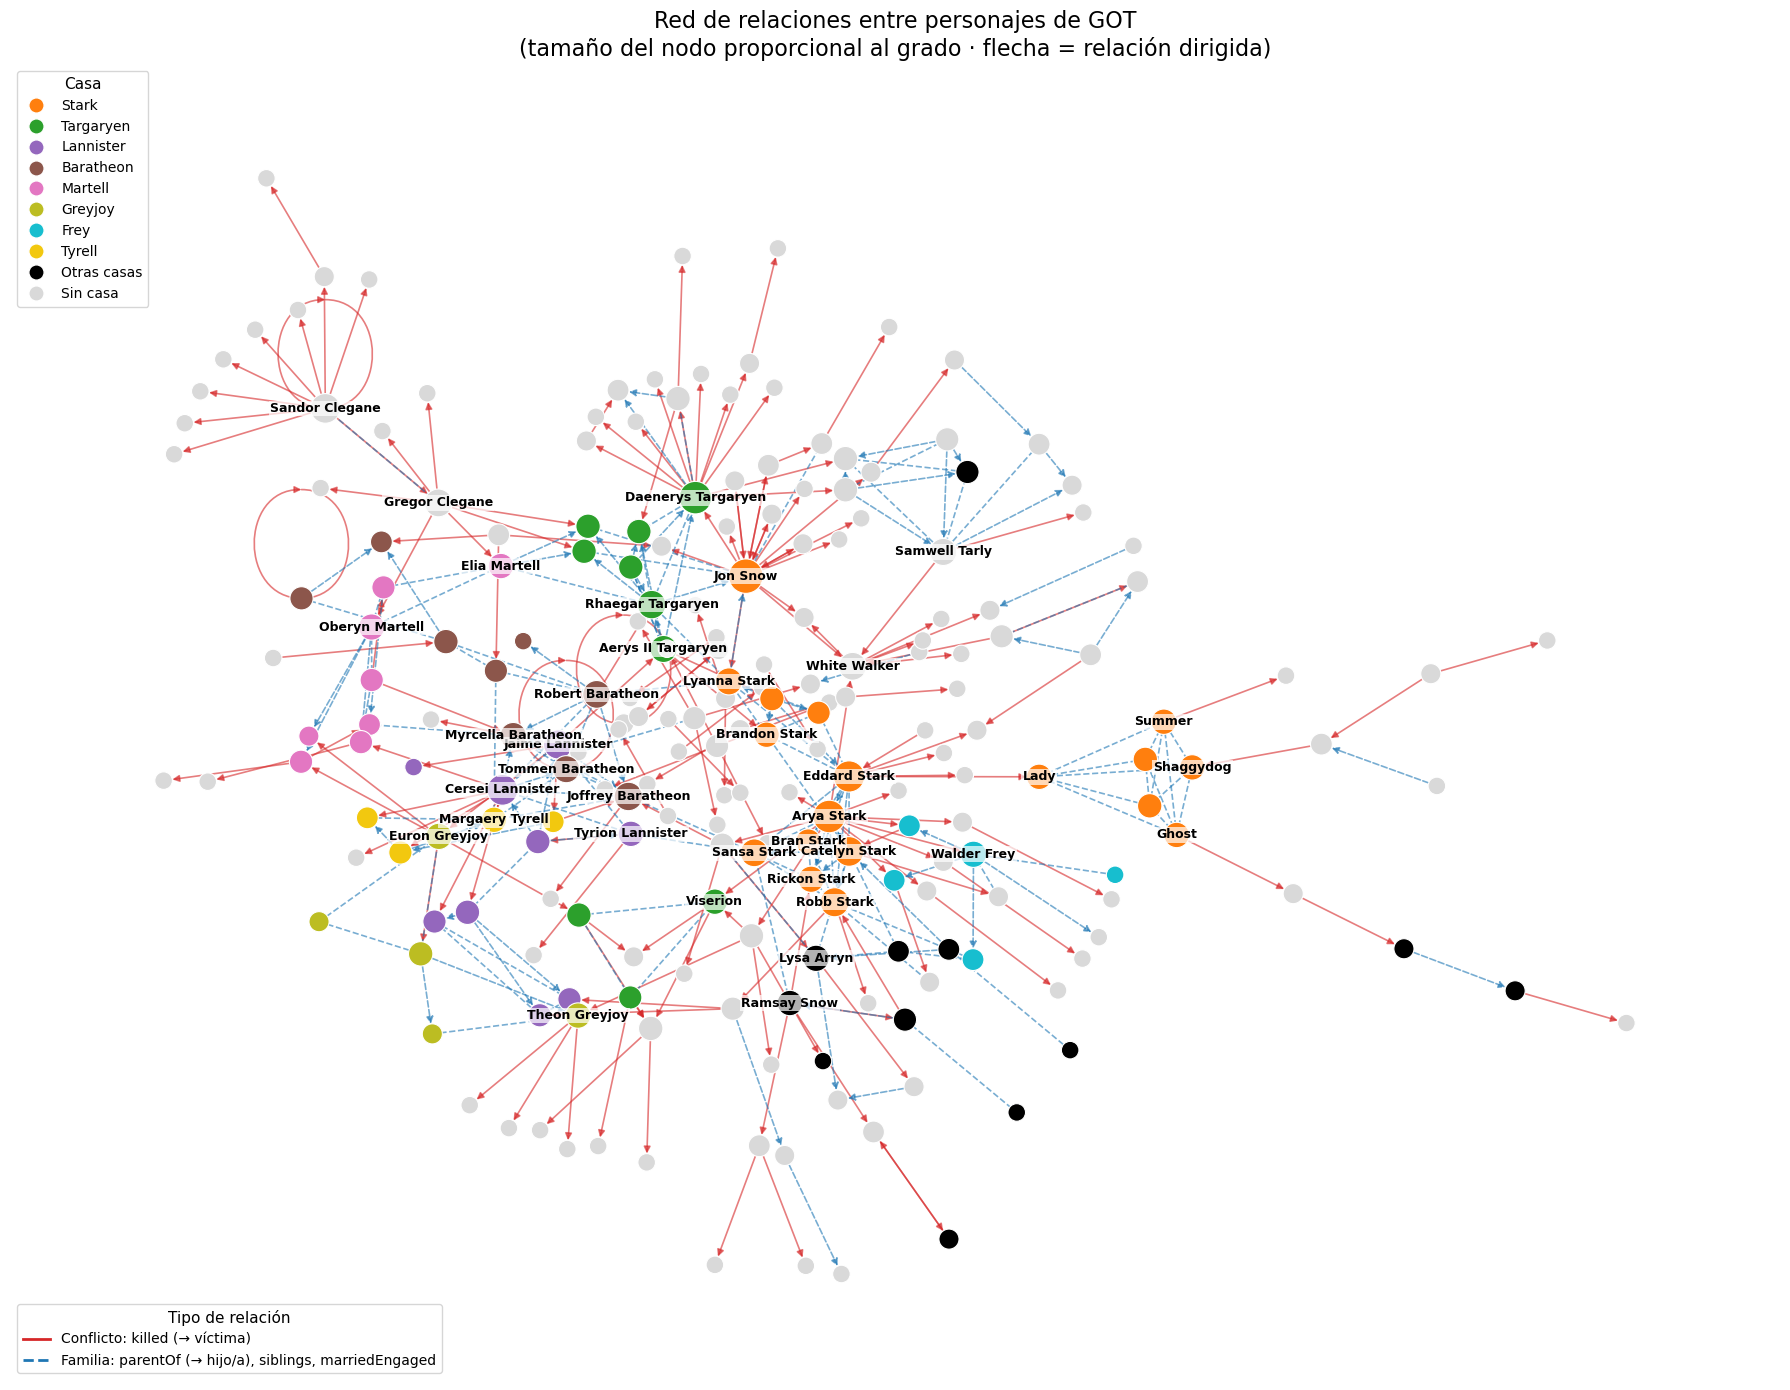

In [8]:
import os

import numpy as np
from matplotlib.lines import Line2D


H = G.subgraph([n for n in G if G.degree(n) > 0])
print("Nodos dibujados:", H.number_of_nodes(), "| Aristas:", H.number_of_edges())



# 2) COLOR DE NODOS POR CASA

conteo_casas = Counter(H.nodes[n]["casa"] for n in H)
CASAS_PRINCIPALES = [c for c, _ in conteo_casas.most_common() if c != "Sin casa"][:8]
# Paleta sin rojos, azules ni grises para no confundirse con las aristas ni con "Sin casa"
PALETA_CASAS = ["#ff7f0e", "#2ca02c", "#9467bd", "#8c564b", "#e377c2", "#bcbd22", "#17becf", "#f2c80f"]
COLOR_CASA = dict(zip(CASAS_PRINCIPALES, PALETA_CASAS))
COLOR_OTRAS = "black"
COLOR_SIN_CASA = "#d9d9d9"


def color_nodo(n):
    casa = H.nodes[n]["casa"]
    if casa == "Sin casa":
        return COLOR_SIN_CASA
    return COLOR_CASA.get(casa, COLOR_OTRAS)


colores_nodos = [color_nodo(n) for n in H]



tamanos_nodos = [40 + 120 * np.sqrt(H.degree(n)) for n in H]


#ESTILO DE ARISTAS POR TIPO

ESTILO_TIPO = {
    "conflicto": {"color": "#d62728", "style": "solid"},
    "familia":   {"color": "#1f77b4", "style": "dashed"},
}



pos = nx.kamada_kawai_layout(nx.Graph(H))



fig, ax = plt.subplots(figsize=(18, 14))

# Aristas una llamada por cada combinación (tipo, dirigida)
for tipo, estilo in ESTILO_TIPO.items():
    for dirigida in (True, False):
        aristas = [(u, v) for u, v, d in H.edges(data=True)
                   if d["tipo"] == tipo and d["dirigida"] == dirigida]
        if not aristas:
            continue
        nx.draw_networkx_edges(
            H, pos, edgelist=aristas, ax=ax,
            edge_color=estilo["color"], style=estilo["style"],
            arrows=dirigida, arrowsize=10,
            width=1.2, alpha=0.6, node_size=tamanos_nodos,
        )


nx.draw_networkx_nodes(H, pos, ax=ax, node_color=colores_nodos,
                       node_size=tamanos_nodos, edgecolors="white", linewidths=0.8)


etiquetas = {n: n for n in H if H.degree(n) >= 6}
nx.draw_networkx_labels(H, pos, labels=etiquetas, ax=ax, font_size=9, font_weight="bold",
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))


leyenda_casas = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=COLOR_CASA[c], markersize=11, label=c)
    for c in CASAS_PRINCIPALES
] + [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=COLOR_OTRAS, markersize=11, label="Otras casas"),
    Line2D([0], [0], marker="o", color="w", markerfacecolor=COLOR_SIN_CASA, markersize=11, label="Sin casa"),
]
leyenda_relaciones = [
    Line2D([0], [0], color=ESTILO_TIPO["conflicto"]["color"], linestyle="solid", lw=2,
           label="Conflicto: killed (→ víctima)"),
    Line2D([0], [0], color=ESTILO_TIPO["familia"]["color"], linestyle="dashed", lw=2,
           label="Familia: parentOf (→ hijo/a), siblings, marriedEngaged"),
]

leyenda1 = ax.legend(handles=leyenda_casas, title="Casa", loc="upper left", fontsize=10, title_fontsize=11)
ax.add_artist(leyenda1)
ax.legend(handles=leyenda_relaciones, title="Tipo de relación", loc="lower left", fontsize=10, title_fontsize=11)

ax.set_title("Red de relaciones entre personajes de GOT\n"
             "(tamaño del nodo proporcional al grado · flecha = relación dirigida)", fontsize=16)
ax.axis("off")
plt.tight_layout()

os.makedirs("graficos", exist_ok=True)
plt.savefig("graficos/1_1_grafo_relaciones.pdf", bbox_inches="tight")
plt.show()


#### Justificación del diseño


### <span style="color: blue;">¿Qué tipo de grafo has decidido utilizar (dirigido, no dirigido o mixto)? ¿Por qué?</span>

Hemos usado un grafo mixto, implementado con un `nx.MultiDiGraph` modificado. Hemos seleccionado cuatro tipos de relación de `characters.json` y cada una se representa según su naturaleza.

- **Dirigidas:** `killed`  y `parentOf` . Notar que buscamos la dirección directa asesino-asesianado, padre-hijo.
- **No dirigidas:** `siblings` y `marriedEngaged`, que son relaciones simétricas.

NetworkX no tiene un tipo de grafo mixto, así que cada arista guarda el atributo `dirigida` y solo las dirigidas se dibujan con flecha. Usamos un multigrafo porque entre dos personajes puede haber varias relaciones a la vez y un grafo simple las fusionaría en una.

Los pares de claves que describen la misma relación desde los dos lados (`killed`/`killedBy` y `parentOf`/`parents`) se normalizan a un único sentido y se eliminan las aristas duplicadas. También descartamos los nombres que no aparecen como personaje en el JSON, para que todos los nodos tengan atributo `casa`.

### <span style="color: blue;">¿Qué criterio has seguido para definir el tamaño y color de los nodos?</span>

- **Tamaño:** depende del **grado** (número total de relaciones), como pide el enunciado. Usamos `40 + 120·√grado`: con una escala lineal los personajes con más relaciones (Jon Snow con 23, Arya y Daenerys con 18) tapaban a los demás, y la raíz comprime esas diferencias sin perder el orden.
- **Color:** indica la **casa** del personaje (`houseName`). Hay 14 casas, pero muchas tienen solo 1–3 personajes, así que asignamos un color a las 8 más numerosas y agrupamos el resto en "Otras casas" (negro). Los personajes sin casa (la mayoría) van en gris claro para que no compitan visualmente con las casas. Hemos excluido el rojo, el azul y el gris de la paleta de casas porque son los colores de las aristas (rojo = conflicto, azul discontinuo = familia) y del grupo "Sin casa".
- **Etiquetas:** solo se muestran los personajes con grado ≥ 6. Usamos el mismo criterio que el tamaño para que los nodos grandes sean los que llevan nombre.
- Los personajes sin ninguna relación (151) no se dibujan, porque solo añadían ruido.

### <span style="color: blue;">¿Qué layout te ha resultado más adecuado para representar las relaciones?</span>

El más adecuado ha sido **Kamada-Kawai**, calculado sobre la versión no dirigida del grafo. Probamos primero `spring_layout` y descartamos esta opción:

- **Sobre el grafo dirigido:** la atracción solo actuaba en el sentido de las aristas, así que las víctimas (que solo reciben flechas) salían despedidas a un anillo exterior y aparecían aristas larguísimas que cruzaban todo el dibujo, fuera cual fuera el valor de `k`.
- **Sobre el no dirigido:** los componentes pequeños se alejaban mucho y el componente principal quedaba comprimido en el centro.

Kamada-Kawai intenta que la distancia en el dibujo sea proporcional a la distancia en el grafo, por lo que las aristas quedan cortas, cada víctima aparece junto a su asesino y las familias quedan agrupadas. Así se aprecian a simple vista los bloques Stark, Targaryen y Lannister/Baratheon, y los personajes que los conectan. La posición se calcula sin dirección, pero las flechas se mantienen en el dibujo.

### Apartado 1.2: Análisis de centralidad y relevancia de personajes

,Grado,Intermediación,Cercanía,Vector propio,PageRank
1,Arya Stark,Arya Stark,Arya Stark,Arya Stark,Jon Snow
2,Jon Snow,Jon Snow,Eddard Stark,Eddard Stark,Daenerys Targaryen
3,Daenerys Targaryen,Eddard Stark,Lyanna Stark,Catelyn Stark,Arya Stark
4,Eddard Stark,White Walker,Jon Snow,Sansa Stark,Sandor Clegane
5,Cersei Lannister,Daenerys Targaryen,White Walker,Robb Stark,Eddard Stark
6,Catelyn Stark,Lady,Rhaegar Targaryen,Rickon Stark,Cersei Lannister
7,Jaime Lannister,Gregor Clegane,Sansa Stark,Bran Stark,White Walker
8,Robb Stark,Lyanna Stark,Aerys II Targaryen,Brandon Stark,Catelyn Stark
9,Sandor Clegane,Rhaegar Targaryen,Catelyn Stark,Lyanna Stark,Robb Stark
10,Joffrey Baratheon,Sansa Stark,Joffrey Baratheon,Joffrey Baratheon,Jaime Lannister


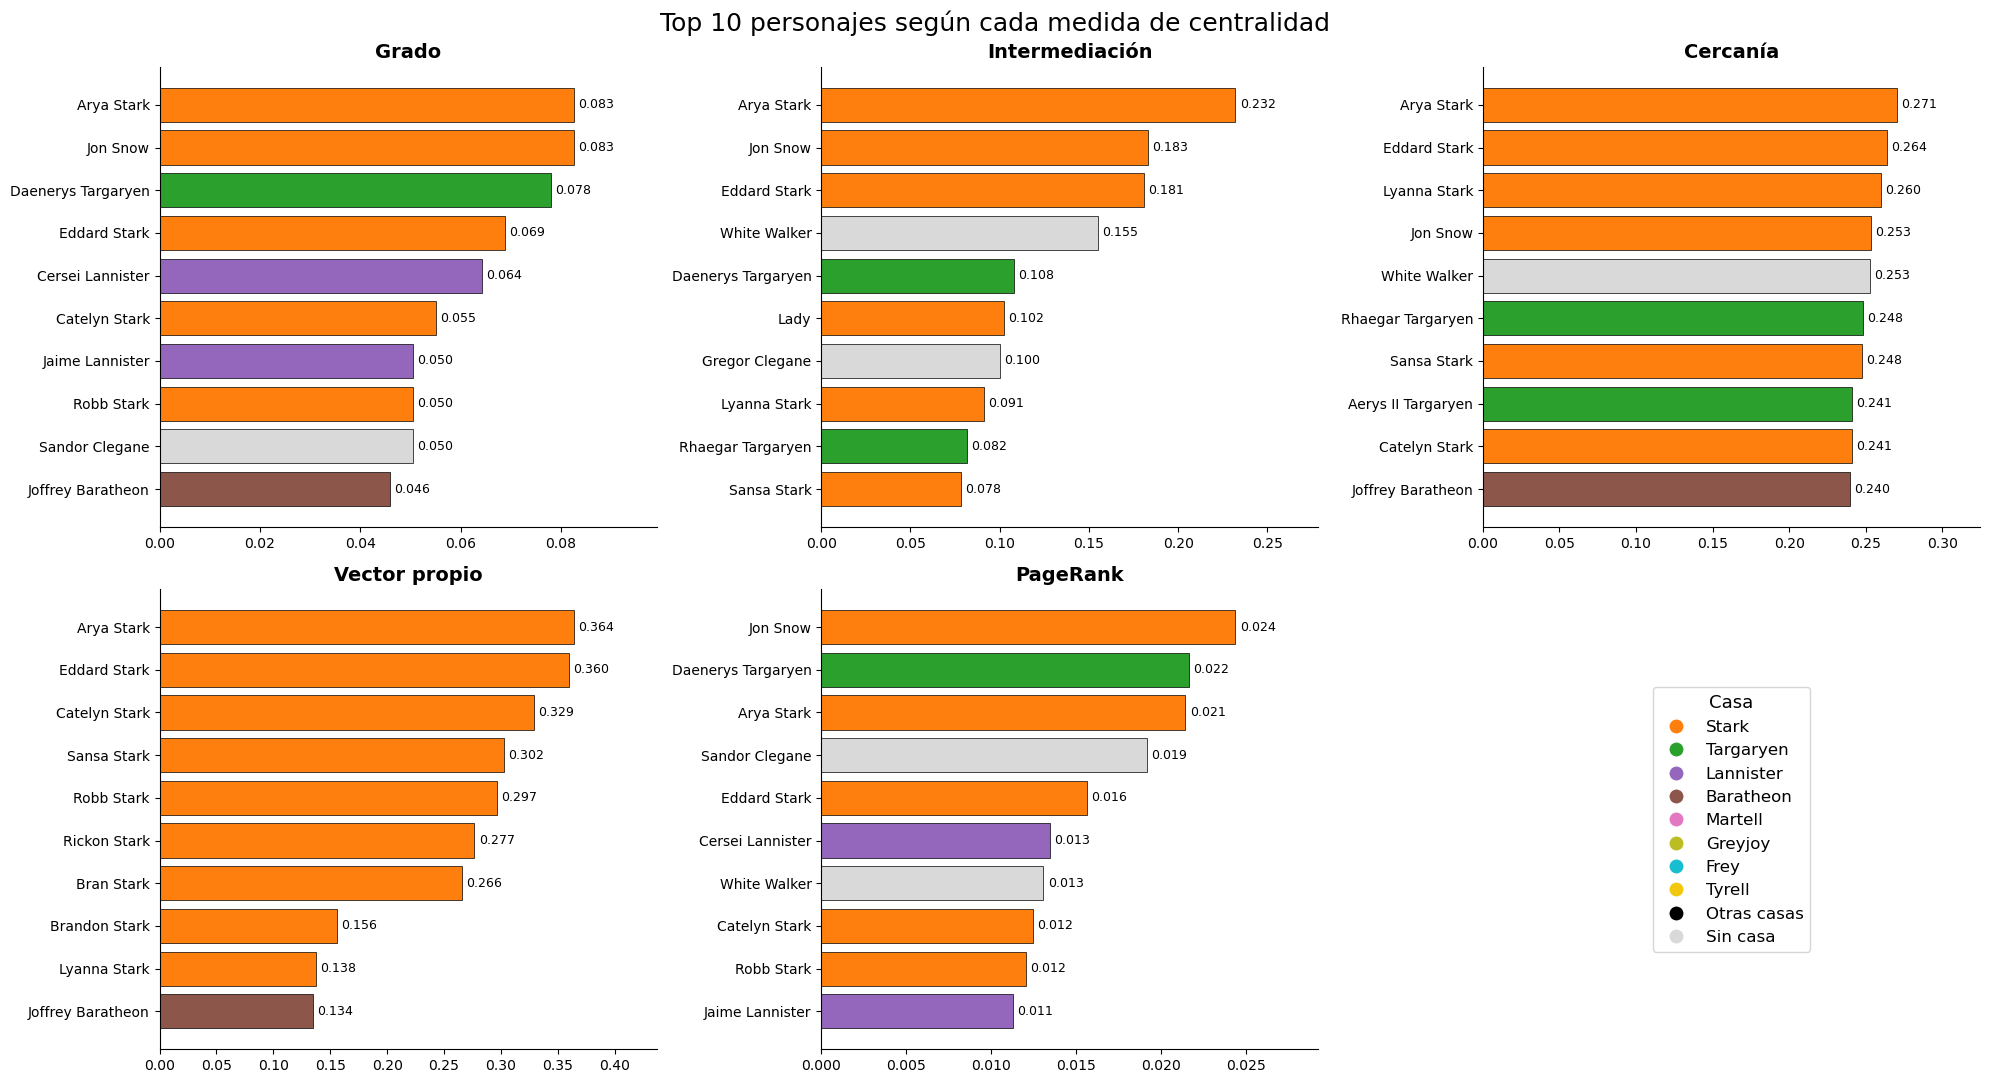

In [9]:
import pandas as pd

# Las métricas se calculan sobre la versión no dirigida y simple del grafo:
# nos interesa con cuántos personajes está conectado cada uno, no el sentido
# ni si hay varias relaciones con la misma persona
U = nx.Graph(H)

METRICAS = {
    "Grado":          nx.degree_centrality(U),
    "Intermediación": nx.betweenness_centrality(U),
    "Cercanía":       nx.closeness_centrality(U),
    "Vector propio":  nx.eigenvector_centrality(U, max_iter=1000),
    "PageRank":       nx.pagerank(U),
}

centralidad = pd.DataFrame(METRICAS)
centralidad["Casa"] = [G.nodes[n]["casa"] for n in centralidad.index]

# Top 10 de cada métrica, uno al lado del otro
top10 = pd.DataFrame({m: centralidad[m].nlargest(10).index.tolist() for m in METRICAS},
                     index=range(1, 11))
display(top10)


fig, axes = plt.subplots(2, 3, figsize=(20, 11))

for ax, metrica in zip(axes.flat, METRICAS):
    top = centralidad.nlargest(10, metrica).iloc[::-1]   # el mayor arriba
    colores = [COLOR_CASA.get(c, COLOR_SIN_CASA if c == "Sin casa" else COLOR_OTRAS) for c in top["Casa"]]

    barras = ax.barh(top.index, top[metrica], color=colores, edgecolor="black", linewidth=0.5)
    ax.bar_label(barras, fmt="%.3f", padding=3, fontsize=9)

    ax.set_title(metrica, fontsize=14, fontweight="bold")
    ax.set_xlim(0, top[metrica].max() * 1.2)
    ax.spines[["top", "right"]].set_visible(False)
    ax.tick_params(axis="y", labelsize=10)

# El sexto hueco se usa para la leyenda de casas
axes.flat[-1].axis("off")
axes.flat[-1].legend(handles=leyenda_casas, title="Casa", loc="center", fontsize=12, title_fontsize=13)

fig.suptitle("Top 10 personajes según cada medida de centralidad", fontsize=18)
plt.tight_layout()
plt.savefig("graficos/1_2_top10_centralidad.pdf", bbox_inches="tight")
plt.show()

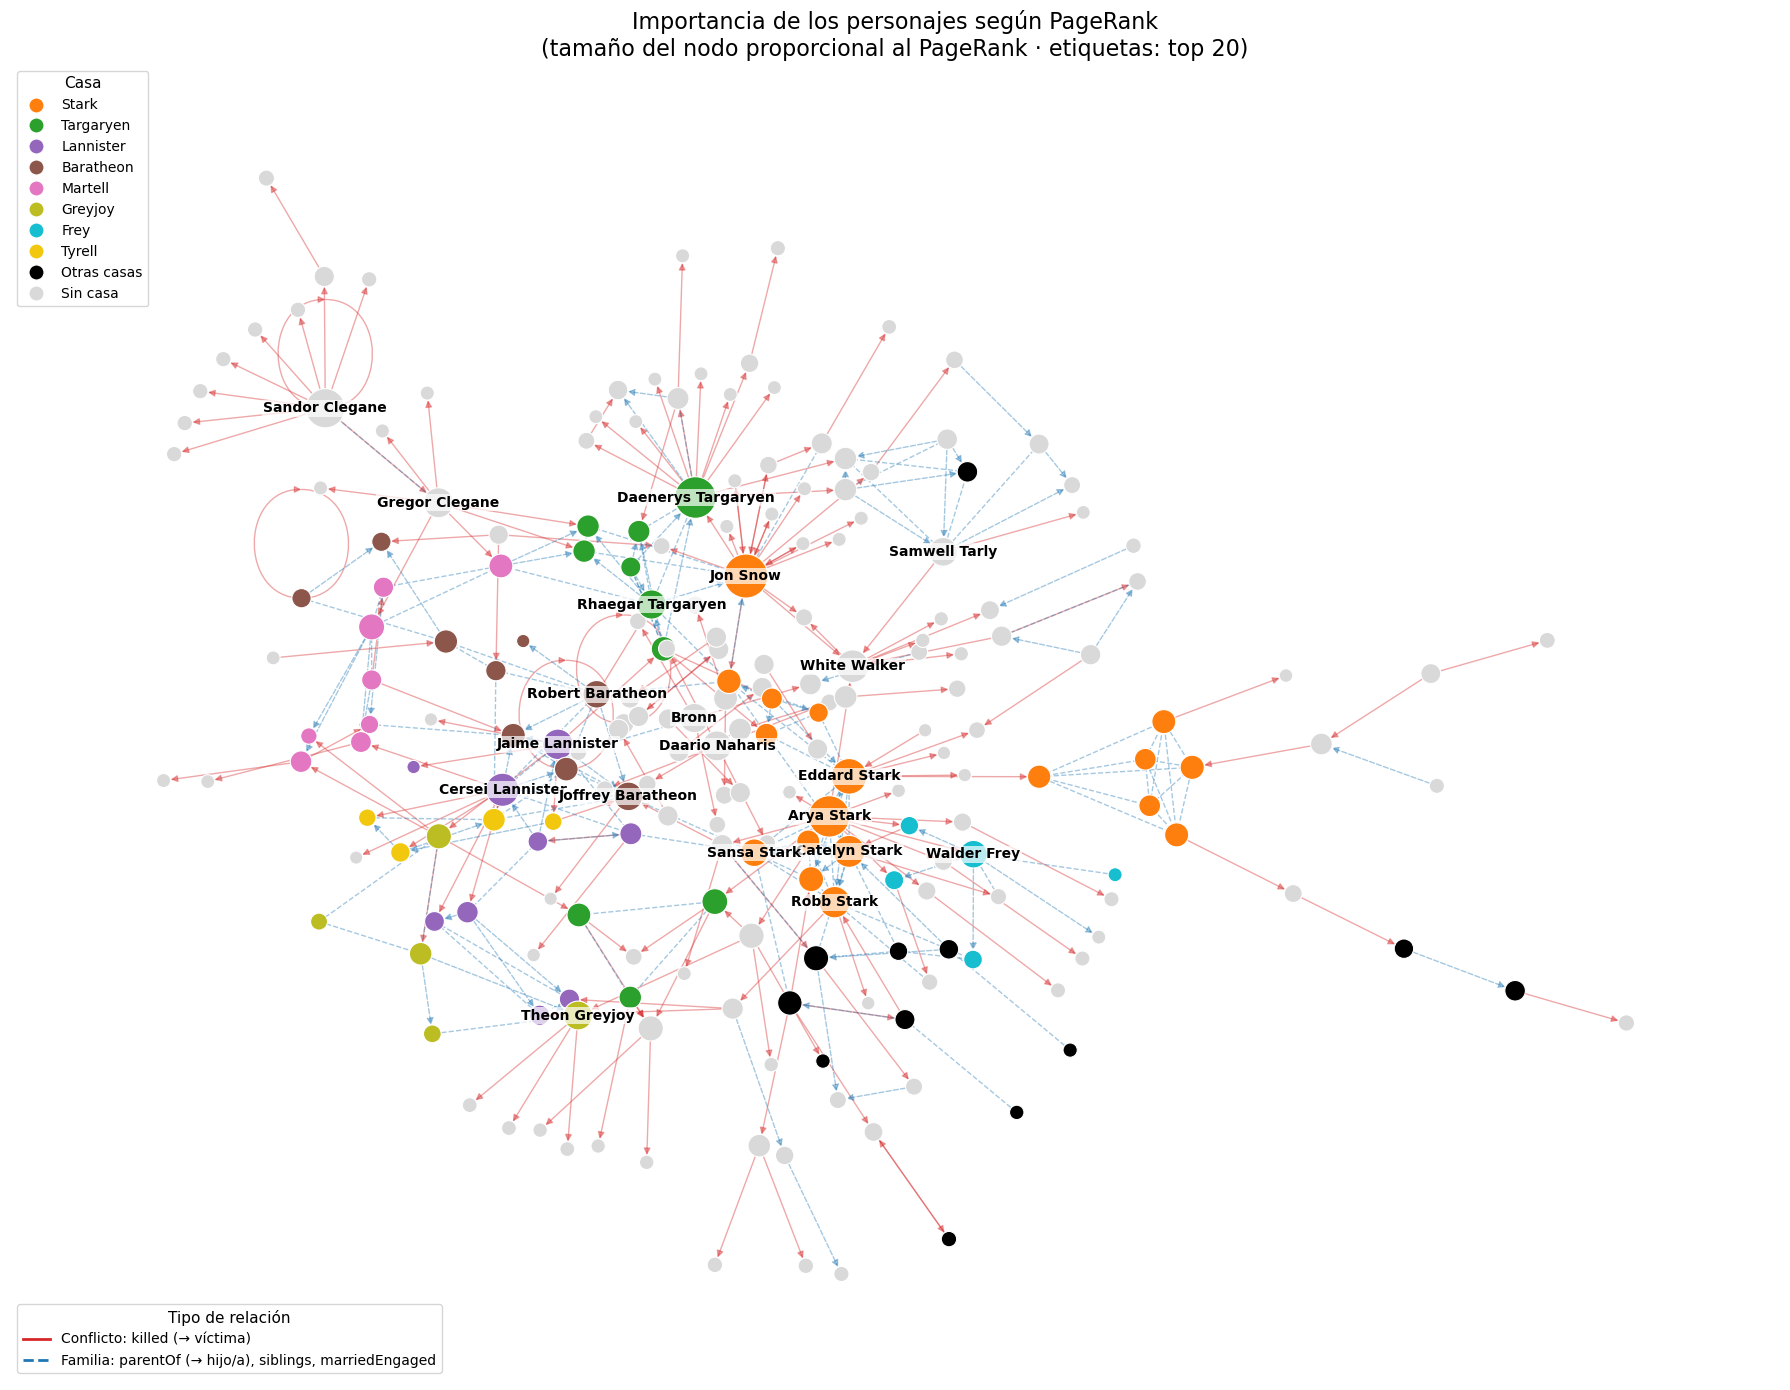

In [10]:
# PageRank: la métrica que mejor refleja la importancia en la historia.
# Mismo layout y colores que en 1.1 para poder comparar ambos grafos
pagerank = centralidad["PageRank"]
tamanos_pr = [30 + 40000 * pagerank[n] for n in H]

fig, ax = plt.subplots(figsize=(18, 14))

for tipo, estilo in ESTILO_TIPO.items():
    for dirigida in (True, False):
        aristas = [(u, v) for u, v, d in H.edges(data=True)
                   if d["tipo"] == tipo and d["dirigida"] == dirigida]
        if not aristas:
            continue
        nx.draw_networkx_edges(
            H, pos, edgelist=aristas, ax=ax,
            edge_color=estilo["color"], style=estilo["style"],
            arrows=dirigida, arrowsize=10,
            width=1.0, alpha=0.4, node_size=tamanos_pr,
        )

nx.draw_networkx_nodes(H, pos, ax=ax, node_color=colores_nodos,
                       node_size=tamanos_pr, edgecolors="white", linewidths=0.8)

# Etiquetas para los 20 personajes con mayor PageRank
etiquetas_pr = {n: n for n in pagerank.nlargest(20).index}
nx.draw_networkx_labels(H, pos, labels=etiquetas_pr, ax=ax, font_size=10, font_weight="bold",
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

leyenda1 = ax.legend(handles=leyenda_casas, title="Casa", loc="upper left", fontsize=10, title_fontsize=11)
ax.add_artist(leyenda1)
ax.legend(handles=leyenda_relaciones, title="Tipo de relación", loc="lower left", fontsize=10, title_fontsize=11)

ax.set_title("Importancia de los personajes según PageRank\n"
             "(tamaño del nodo proporcional al PageRank · etiquetas: top 20)", fontsize=16)
ax.axis("off")
plt.tight_layout()
plt.savefig("graficos/1_2_grafo_pagerank.pdf", bbox_inches="tight")
plt.show()

#### Justificación del diseño

- **Negrita:** Normal 

Las métricas se calculan sobre la versión no dirigida y simple del grafo (`nx.Graph(H)`), porque queremos medir lo conectado que está cada personaje, no el sentido de la relación ni si hay varias con la misma persona. Para el top 10 usamos un gráfico de barras horizontales por métrica (los nombres largos se leen mejor en el eje Y), con el valor escrito al final de cada barra y coloreado por casa con la misma paleta que el grafo del 1.1. El sexto hueco de la rejilla se aprovecha para la leyenda.

### <span style="color: blue;">¿Qué diferencias observas entre las distintas medidas de centralidad?</span>

- **Grado:** cuenta relaciones directas. Destacan los personajes con muchas muertes o mucha familia: Arya, Jon, Daenerys, Eddard y Cersei.
- **Intermediación:** mide cuántos caminos más cortos pasan por un nodo, es decir, quién hace de **puente** entre grupos. Aparecen personajes que no tienen tantas relaciones pero conectan zonas de la red.
- **Cercanía:** valora lo cerca que está un nodo de todos los demás. Sus valores están muy comprimidos y premia a los personajes situados en el centro geométrico de la red, como Lyanna, Rhaegar o Aerys II, que tienen pocas relaciones pero están a pocos saltos de todo.
- **Vector propio:** da más peso a estar conectado con nodos que a su vez son importantes. Como la familia Stark es un bloque muy denso y muy conectado entre sí, los 9 primeros son Stark. Esta medida refleja más la densidad de un grupo que la importancia individual.
- **PageRank:** es parecido al grado, pero pondera la importancia de los vecinos y evita que un único grupo denso acapare el ranking. Su top 10 mezcla varias casas: Jon, Daenerys, Arya, Sandor, Eddard, Cersei, Catelyn, Robb y Jaime.

### <span style="color: blue;">¿Los personajes más “centrales” coinciden con los más importantes en la historia?</span>

En gran parte sí, sobre todo con **grado y PageRank**: Jon Snow, Daenerys, Arya, Eddard, Cersei o Jaime son protagonistas de la serie. Las demás métricas introducen ruido o sesgos:

- La **intermediación** y la **cercanía** cuelan personajes secundarios (Lady, el White Walker, Rhaegar, Aerys II) por su posición estructural, no por su peso en la trama.
- El **vector propio** está sesgado hacia los Stark y deja fuera a Daenerys o Jon.

Por eso, para la visualización final usamos **PageRank**: su top 10 es el que más se parece al reparto principal de la serie y no está dominado por una sola casa. En ese grafo el tamaño es lineal con el PageRank (no con la raíz), para que se aprecie bien el salto entre los protagonistas y el resto. Se mantienen el layout y los colores del 1.1 para poder comparar los dos grafos directamente.

### <span style="color: blue;"> ¿Cómo influye la forma de calcular la centralidad en la interpretación del grafo?</span>

Cada métrica responde a una pregunta distinta, así que "el personaje más importante" cambia según cuál se elija:

- **Grado:** ¿quién tiene más relaciones?
- **Intermediación:** ¿quién conecta grupos que de otro modo estarían separados?
- **Cercanía:** ¿quién está más cerca de todos?
- **Vector propio y PageRank:** ¿quién está conectado con personajes importantes?

Además, el resultado depende de **qué relaciones se incluyan**. Como `killed` es la relación más numerosa (180 de 361 aristas), los personajes que matan mucho (Arya, Daenerys, Sandor) suben en todas las métricas. Con solo relaciones familiares el ranking sería muy diferente. Por tanto, la centralidad no es una medida absoluta de importancia, sino una forma de leer la estructura de la red según el criterio elegido.

### Apartado 1.3: Subredes y comunidades

Subgrafo familiar: 109 nodos | 180 aristas
Comunidades detectadas: 19 | Modularidad: 0.794


,Miembros,Casa mayoritaria,Composición por casa
C1,17,Baratheon,"{'Baratheon': 9, 'Lannister': 4, 'Tyrell': 4}"
C2,14,Frey,"{'Sin casa': 5, 'Frey': 5, 'Tully': 3, 'Arryn'..."
C3,12,Targaryen,"{'Targaryen': 7, 'Sin casa': 3, 'Stark': 1, 'M..."
C4,12,Stark,"{'Stark': 11, 'Sin casa': 1}"
C5,8,Tarly,"{'Sin casa': 7, 'Tarly': 1}"
C6,7,Martell,{'Martell': 7}
C7,6,Stark,{'Stark': 6}
C8,5,Greyjoy,{'Greyjoy': 5}


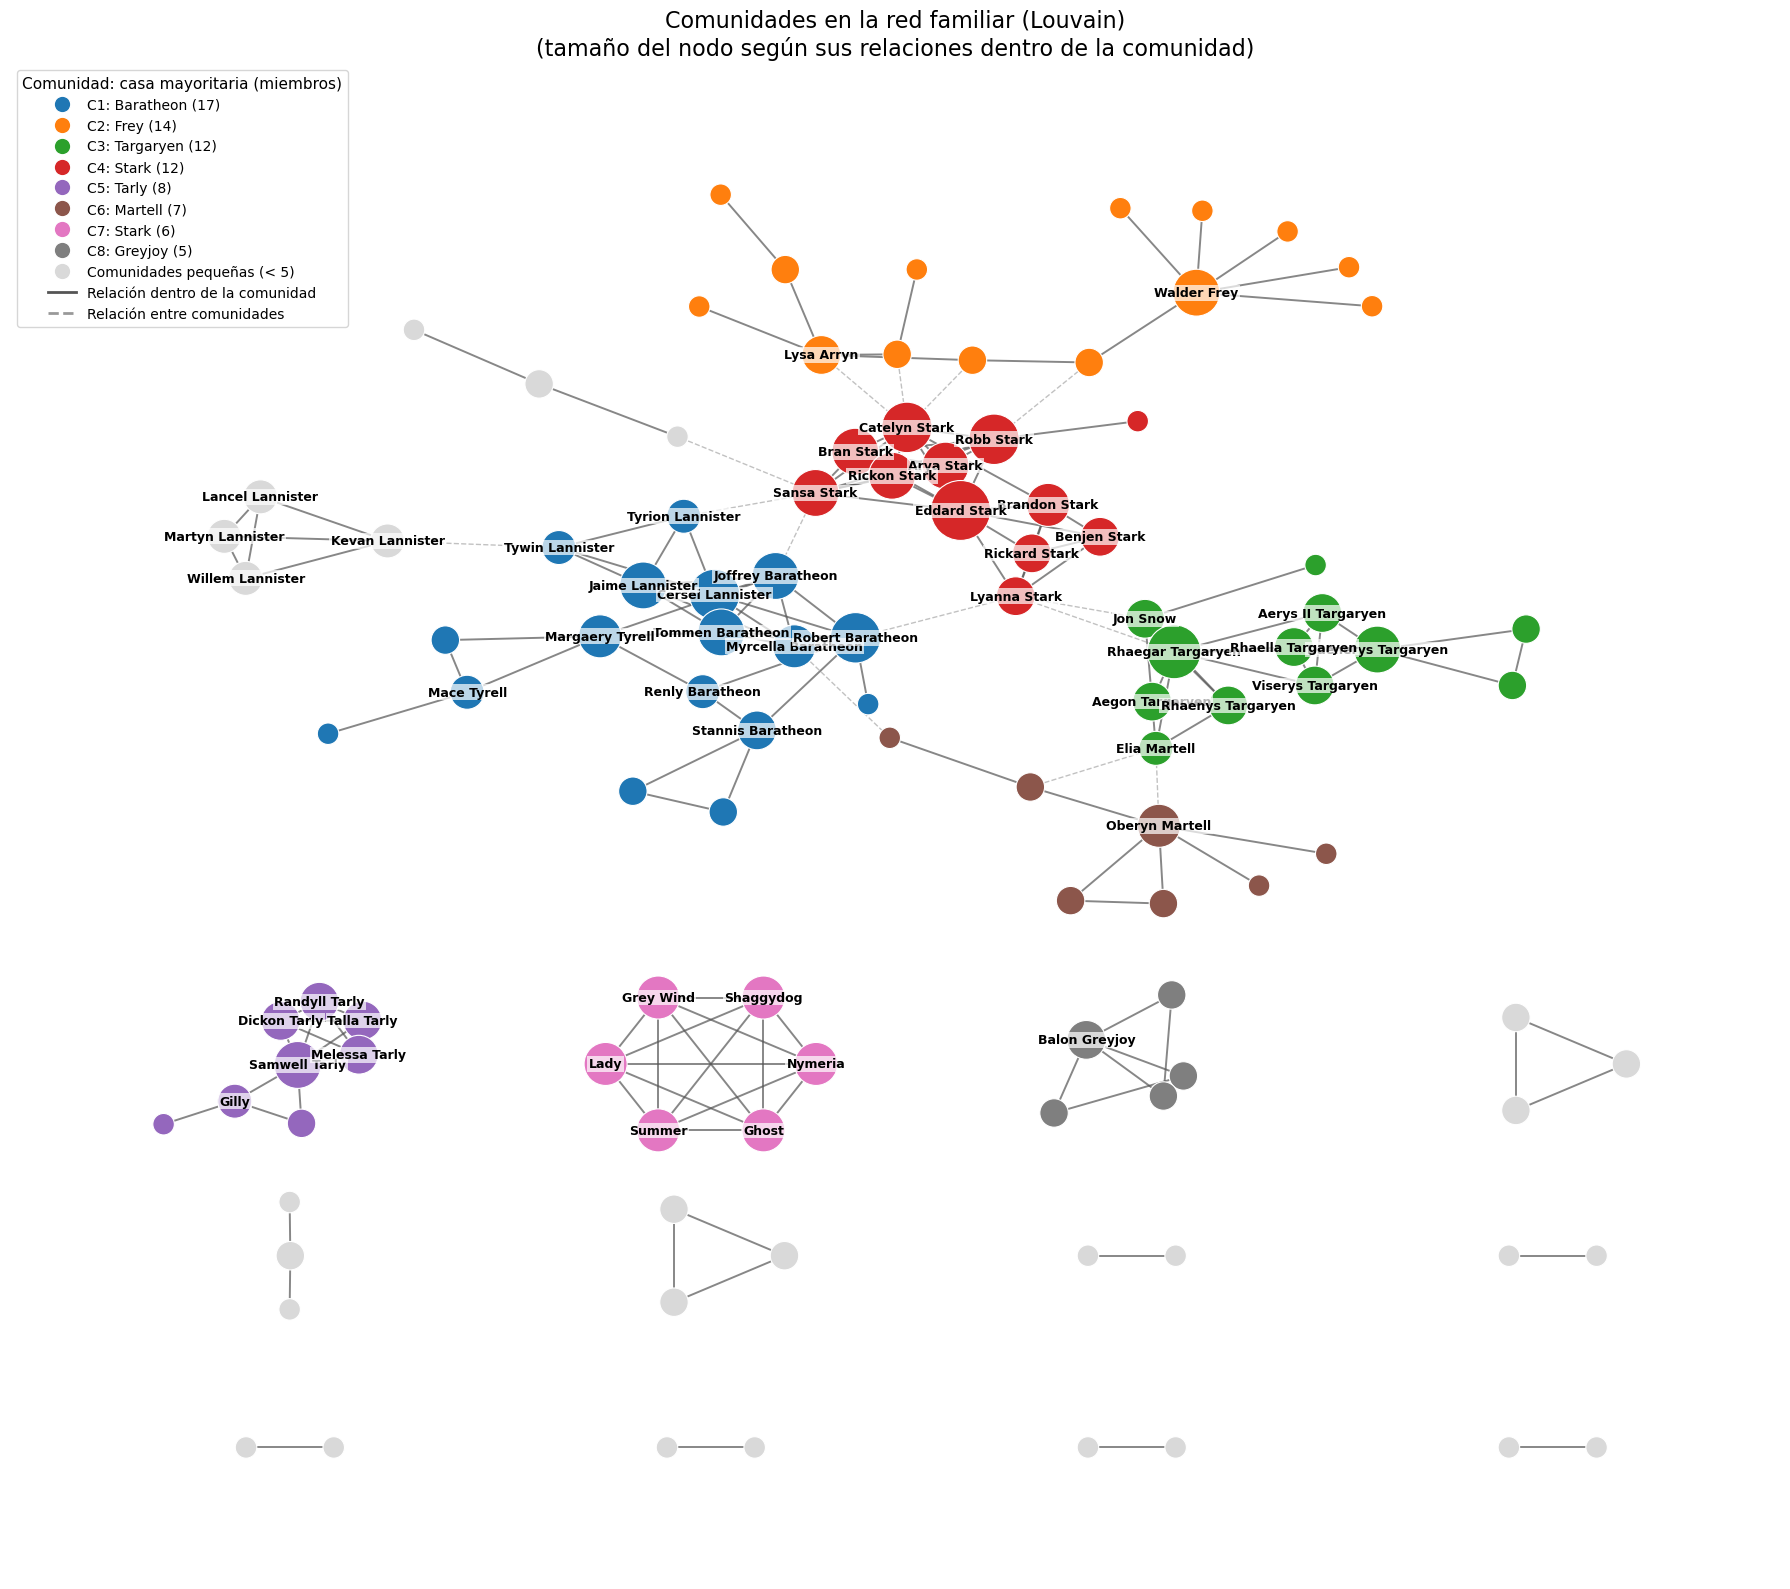

In [11]:
# Subgrafo de relaciones familiares (parentOf, siblings, marriedEngaged) como
# grafo no dirigido: para detectar grupos solo importa quién está unido a quién
familia = nx.Graph()
familia.add_edges_from((u, v) for u, v, d in G.edges(data=True) if d["tipo"] == "familia")
print("Subgrafo familiar:", familia.number_of_nodes(), "nodos |", familia.number_of_edges(), "aristas")

comunidades = sorted(nx.community.louvain_communities(familia, seed=42), key=len, reverse=True)
print("Comunidades detectadas:", len(comunidades),
      "| Modularidad:", round(nx.community.modularity(familia, comunidades), 3))

# Comunidades principales: las de 5 o más personajes
MIN_MIEMBROS = 5
principales = [c for c in comunidades if len(c) >= MIN_MIEMBROS]

comunidad_de = {n: i for i, c in enumerate(comunidades) for n in c}


def casa_mayoritaria(c):
    casas = Counter(G.nodes[n]["casa"] for n in c if G.nodes[n]["casa"] != "Sin casa")
    return casas.most_common(1)[0][0] if casas else "Sin casa"


resumen = pd.DataFrame({
    "Miembros": [len(c) for c in principales],
    "Casa mayoritaria": [casa_mayoritaria(c) for c in principales],
    "Composición por casa": [dict(Counter(G.nodes[n]["casa"] for n in c).most_common()) for c in principales],
}, index=[f"C{i + 1}" for i in range(len(principales))])
display(resumen)


PALETA_COMUNIDADES = plt.cm.tab10.colors
COLOR_SECUNDARIA = "#d9d9d9"

colores_com = [PALETA_COMUNIDADES[comunidad_de[n]] if comunidad_de[n] < len(principales)
               else COLOR_SECUNDARIA for n in familia]

# Tamaño según el nº de relaciones con miembros de su misma comunidad
grado_interno = {n: sum(1 for v in familia[n] if comunidad_de[v] == comunidad_de[n]) for n in familia}
tamanos_com = [60 + 180 * grado_interno[n] for n in familia]


def layout_por_componentes(grafo, columnas=4):
    """Kamada-Kawai para cada componente conexo por separado. El componente
    principal ocupa la parte superior y los demás se reparten en una rejilla
    debajo, con un tamaño proporcional a su número de nodos."""
    componentes = sorted(nx.connected_components(grafo), key=len, reverse=True)
    posiciones = {}

    principal = grafo.subgraph(componentes[0])
    for n, (x, y) in nx.kamada_kawai_layout(principal).items():
        posiciones[n] = np.array([x * 2.0, y * 1.4 + 0.5])

    for i, comp in enumerate(componentes[1:]):
        fila, col = divmod(i, columnas)
        centro = np.array([-1.8 + col * 1.2, -1.5 - fila * 0.75])
        if len(comp) > 2:
            local = nx.kamada_kawai_layout(grafo.subgraph(comp), scale=0.12 + 0.03 * len(comp))
        else:
            local = {n: np.array([(j - 0.5) * 0.25, 0]) for j, n in enumerate(comp)}
        for n, p in local.items():
            posiciones[n] = centro + p
    return posiciones


pos_fam = layout_por_componentes(familia)

fig, ax = plt.subplots(figsize=(18, 16))

# Aristas internas más marcadas que las que unen comunidades distintas
internas = [(u, v) for u, v in familia.edges() if comunidad_de[u] == comunidad_de[v]]
externas = [(u, v) for u, v in familia.edges() if comunidad_de[u] != comunidad_de[v]]
nx.draw_networkx_edges(familia, pos_fam, edgelist=internas, ax=ax, edge_color="#555555", width=1.4, alpha=0.7)
nx.draw_networkx_edges(familia, pos_fam, edgelist=externas, ax=ax, edge_color="#999999",
                       width=1.0, alpha=0.6, style="dashed")

nx.draw_networkx_nodes(familia, pos_fam, ax=ax, node_color=colores_com,
                       node_size=tamanos_com, edgecolors="white", linewidths=0.8)

etiquetas_com = {n: n for n in familia if grado_interno[n] >= 3}
nx.draw_networkx_labels(familia, pos_fam, labels=etiquetas_com, ax=ax, font_size=9, font_weight="bold",
                        bbox=dict(facecolor="white", edgecolor="none", alpha=0.7, pad=1))

leyenda_com = [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=PALETA_COMUNIDADES[i], markersize=12,
           label=f"C{i + 1}: {resumen.iloc[i]['Casa mayoritaria']} ({len(c)})")
    for i, c in enumerate(principales)
] + [
    Line2D([0], [0], marker="o", color="w", markerfacecolor=COLOR_SECUNDARIA, markersize=12,
           label=f"Comunidades pequeñas (< {MIN_MIEMBROS})"),
    Line2D([0], [0], color="#555555", lw=2, label="Relación dentro de la comunidad"),
    Line2D([0], [0], color="#999999", lw=2, linestyle="dashed", label="Relación entre comunidades"),
]
ax.legend(handles=leyenda_com, title="Comunidad: casa mayoritaria (miembros)", loc="upper left",
          fontsize=10, title_fontsize=11)

ax.set_title("Comunidades en la red familiar (Louvain)\n"
             "(tamaño del nodo según sus relaciones dentro de la comunidad)", fontsize=16)
ax.axis("off")
plt.tight_layout()
plt.savefig("graficos/1_3_comunidades_familia.pdf", bbox_inches="tight")
plt.show()

#### Justificación del diseño

- **Negrita:** Normal 

Hemos trabajado con el **subgrafo de relaciones familiares** (`parentOf`, `siblings` y `marriedEngaged`), tratado como no dirigido: para detectar grupos solo importa quién está unido a quién. Tiene 109 personajes y 180 aristas. Para detectar las comunidades usamos el algoritmo de **Louvain** (`nx.community.louvain_communities`), que maximiza la modularidad. Fijamos `seed=42` para que el resultado sea reproducible.

### <span style="color: blue;">¿Cuántas comunidades principales has identificado?</span>

Louvain encuentra **19 comunidades**, con una modularidad de **0.79**. Un valor tan alto indica que la red familiar está muy bien dividida en grupos. Muchas de esas comunidades son parejas o tríos sueltos, así que consideramos **principales las 8 que tienen 5 o más miembros**:

| Comunidad | Miembros | Composición |
|---|---|---|
| C1 | 17 | Baratheon + Lannister + Tyrell |
| C2 | 14 | Frey + Tully + Arryn |
| C3 | 12 | Targaryen (+ Elia Martell, Khal Drogo, Jon Snow) |
| C4 | 12 | Stark |
| C5 | 8 | Tarly + Gilly y Craster |
| C6 | 7 | Martell y las Serpientes de Arena |
| C7 | 6 | Los huargos de los Stark |
| C8 | 5 | Greyjoy |

### <span style="color: blue;">¿Coinciden estas comunidades con las casas nobles aliadas o algún patrón que se pueda reconocer de la serie?</span>

Sí. Para comprobarlo hemos cruzado cada comunidad con el atributo `houseName` del dataset (tabla `resumen`) y con el tipo de relación de sus aristas. Salen tres patrones claros.

**1. Comunidades que son una sola casa.** Coinciden casi al 100 % con el apellido:
- **C4 (Stark):** 11 de 12 miembros son Stark. La única excepción es Talisa Maegyr, que está casada con Robb Stark.
- **C6 (Martell):** sus 7 miembros son Martell.
- **C8 (Greyjoy):** sus 5 miembros son Greyjoy.
- **C5 (Tarly):** casi todos llevan el apellido Tarly, aunque en `houseName` solo uno la tiene informada. Incluye también a Gilly y Craster, por el matrimonio entre Samwell Tarly y Gilly.

**2. Comunidades que juntan varias casas unidas por matrimonios (alianzas).** Aquí la comunidad no es una familia de sangre, sino casas enlazadas por bodas:
- **C1 (Baratheon + Lannister + Tyrell):** el algoritmo las agrupa por matrimonios entre ellas registrados en los datos: Cersei Lannister con Robert Baratheon, y Joffrey y Tommen Baratheon con Margaery Tyrell. Son las casas que en la serie comparten el poder en la capital.
- **C2 (Frey + Tully + Arryn):** se agrupan por los parentescos entre ellas (Hoster Tully es padre de Lysa Arryn, que a su vez es madre de Robin Arryn junto a Jon Arryn) y por los matrimonios de Lysa con Petyr Baelish y de Edmure Tully con Roslin Frey.

**3. Patrones que no siguen la casa del personaje.**
- **Jon Snow** está registrado como Stark, pero el algoritmo lo coloca con los **Targaryen (C3)**: en los datos su padre es Rhaegar Targaryen y sus hermanos son Aegon y Rhaenys Targaryen. Es decir, las relaciones familiares del dataset dicen más sobre su origen que el apellido.
- Los **huargos** (los lobos de los hijos Stark) forman su propia comunidad (C7), porque en el dataset solo tienen relaciones `siblings` entre ellos.
- La familia **Lannister se reparte**: Cersei, Jaime, Tyrion y Tywin están en C1 con los Baratheon, mientras que la rama de Kevan Lannister forma un componente aparte, sin relaciones con el resto.

Por último, las aristas que unen comunidades distintas son casi todas **matrimonios** y casi todas pasan por los **Stark**: Robb con Roslin Frey, Sansa con Joffrey y con Tyrion, Lyanna con Robert Baratheon y con Rhaegar Targaryen, y Catelyn, que es hermana de Lysa y de Edmure Tully. Así, la familia Stark actúa como **puente entre las grandes casas**, lo que encaja con lo que vimos en el 1.2: los Stark dominan las métricas de centralidad.

### <span style="color: blue;">¿Qué decisiones de diseño (colores, tamaño, layout) te han ayudado a mejorar la legibilidad del grafo?</span>

- **Color:** una paleta categórica (`tab10`) con un color por comunidad principal. Las 11 comunidades pequeñas van en gris claro para no saturar la leyenda con colores que apenas aportan información. La leyenda muestra la casa mayoritaria y el número de miembros de cada comunidad, para poder interpretarla sin consultar la tabla.
- **Tamaño:** según el **grado interno**, es decir, el número de relaciones con miembros de la misma comunidad, como pide el enunciado. Así destacan los núcleos de cada familia (Eddard y Catelyn, Rhaegar, Oberyn, Walder Frey).
- **Aristas:** las internas son continuas y más oscuras, y las que unen comunidades distintas son discontinuas y más claras. Así se distinguen a simple vista los puentes entre familias (por ejemplo, Lyanna Stark – Rhaegar Targaryen o Sansa Stark – Tyrion Lannister).
- **Layout:** el subgrafo familiar tiene 13 componentes desconectados. Con Kamada-Kawai sobre todo el grafo, los componentes pequeños (Tarly, huargos, Greyjoy) se colocaban encima del grupo Baratheon. Por eso hemos implementado `layout_por_componentes`, que aplica Kamada-Kawai a **cada componente por separado**: el principal ocupa la parte superior y los pequeños se reparten en una rejilla debajo.
- **Etiquetas:** solo se muestran los personajes con al menos 3 relaciones internas, para evitar que se solapen.

## Apartado 2: Visualización de datos geográficos con Folium

### Apartado 2.1: Preparar el mapa base de Juego de Tronos

#### Justificación del diseño

- **Negrita:** Normal 

### <span style="color: blue;">¿Qué capa base (tiles) has utilizado y por qué?</span>

Respuesta

### <span style="color: blue;">¿Cómo has definido los colores o estilos para distinguir tierra y mar?</span>

Respuesta

### <span style="color: blue;">¿Cómo has implementado la función para obtener los valores para ajustar el zoom y centro del mapa para mejorar la visualización?</span>

Respuesta

### Apartado 2.2: Mostrar la importancia de cada ubicación

#### Justificación del diseño

- **Negrita:** Normal 

### <span style="color: blue;">¿Qué criterio has seguido para definir el tamaño y color de los círculos?</span>

Respuesta

### <span style="color: blue;">¿Qué información has decidido incluir en los popups y por qué?</span>

Respuesta

### <span style="color: blue;">¿Qué tipo de capa o fondo permite visualizar mejor la distribución de los puntos?</span>

Respuesta

### Apartado 2.3: Visualizar la ruta de lugares en un episodio

#### Justificación del diseño

- **Negrita:** Normal 

### <span style="color: blue;">¿Qué decisiones de diseño has tomado para mejorar la visualización del seguimiento de las rutas en los episodios (por número de apariciones, por orden cronológico, …)</span>

Respuesta

## Apartado Opcional: Visualización de grafos con PyVis

### Apartado 3.1: Física del grafo y legibilidad básica

#### Justificación del diseño

- **Negrita:** Normal 

### <span style="color: blue;"> ¿Qué configuración de física ofrece mejor separación de comunidades y menor solapamiento de etiquetas?</span>

Respuesta

### <span style="color: blue;">¿Cómo afecta el damping y la central gravity a la estabilidad del layout?</span>

Respuesta

### <span style="color: blue;">¿Por qué el tamaño de nodo elegido mejora (o no) la lectura de la importancia de los personajes?</span>

Respuesta

### Apartado 3.2: Interacción enriquecida

#### Justificación del diseño

- **Negrita:** Normal 

### <span style="color: blue;">¿Qué información incluiste en los tooltips y por qué?</span>

Respuesta

### <span style="color: blue;">¿Qué criterio seguiste para decidir qué etiquetas se muestran por defecto?</span>

Respuesta

### <span style="color: blue;">¿Qué otros criterios de diseño has aplicado al grafo para mejorar su visibilidad e interacción?</span>

Respuesta